&nbsp;
# <div align=center><font color=green> <span style="background-color: #e6f7ff; padding: 2px; color: green; font-family: monospace;">Scikit-learn</span> : Dimension Reduction</font></div>
<!-- # <div align=center> Part II </div> -->
## <div align=center>Yixin Yan & Ziping Zhao</div>

**<div align=center> School of Information Science and Technology </div>**
**<div align=center>ShanghaiTech University, Shanghai, China</div>**

**<div align=center><font size="7">CS182: Introduction to Machine Learning<font/></div>**
    
**<div align=center><font size="7">http://cs182.sist.shanghaitech.edu.cn<font/></div>**

### <div align=center><font color=green> Sec. 2.5 of  <span style="background-color: #e6f7ff; padding: 2px; color: green; font-family: monospace;">Scikit-learn</span> </font></div>

## Dimension Reduction

## Feature Selection in `sklearn.feature_selection`

- The class in `sklearn.feature_selection` can be used for feature selection/dimensionality reduction.

- Improve estimator's accuracy scores or boost their performance on very high-dimensional datasets.

## Removing features with low variance

- `VarianceThreshold` is a simple baseline approach to feature selection, which removes all features whose variance doesn't meet some threshold.

- By default, it removes all zero-variance features, i.e. features that have the same value in all samples.

- Suppose we have a dataset with boolean features, and we want to remove all features that are either one or zero in more that 80% of the samples.

- Boolean features are Bernoulli random variables, and the variance of such variables is given by

$$\text{Var}[X]=p(1-p).$$

- We select using the threshold $0.8*(1-0.8)$

In [1]:
from sklearn.feature_selection import VarianceThreshold
?VarianceThreshold

Init signature: VarianceThreshold(threshold=0.0)
Docstring:     
Feature selector that removes all low-variance features.

This feature selection algorithm looks only at the features (X), not the
desired outputs (y), and can thus be used for unsupervised learning.

Read more in the :ref:`User Guide <variance_threshold>`.

Parameters
----------
threshold : float, default=0
    Features with a training-set variance lower than this threshold will
    be removed. The default is to keep all features with non-zero variance,
    i.e. remove the features that have the same value in all samples.

Attributes
----------
variances_ : array, shape (n_features,)
    Variances of individual features.

n_features_in_ : int
    Number of features seen during :term:`fit`.

    .. versionadded:: 0.24

feature_names_in_ : ndarray of shape (`n_features_in_`,)
    Names of features seen during :term:`fit`. Defined only when `X`
    has feature names that are all strings.

    .. versionadded:: 1.0

See Also

In [2]:
from sklearn.feature_selection import VarianceThreshold
X = [[0, 0, 1], [0, 1, 0], [1, 0, 0], [0, 1, 1], [0, 1, 0], [0, 1, 1]]
sel = VarianceThreshold(threshold=(.8 * (1 - .8)))
sel.fit_transform(X)

array([[0, 1],
       [1, 0],
       [0, 0],
       [1, 1],
       [1, 0],
       [1, 1]])

As expected, `VarianceThreshold` has removed the first column, which has a probability $p=5/6>0.8$ of containing a zero.

## Sequential Feature Selection (SFS)

- SFS can be either forward or backward

- Forward-SFS is a greedy procedure that iteratively finds the best new feature to add to the set of selected features.

- Backward-SFS start with all the features and greedily remove features from the set.

- In general, forward and backward selection do not yield equivalent results.

In [3]:
from sklearn.feature_selection import SequentialFeatureSelector
?SequentialFeatureSelector

Init signature:
SequentialFeatureSelector(
    estimator,
    *,
    n_features_to_select='auto',
    tol=None,
    direction='forward',
    scoring=None,
    cv=5,
    n_jobs=None,
)
Docstring:     
Transformer that performs Sequential Feature Selection.

This Sequential Feature Selector adds (forward selection) or
removes (backward selection) features to form a feature subset in a
greedy fashion. At each stage, this estimator chooses the best feature to
add or remove based on the cross-validation score of an estimator. In
the case of unsupervised learning, this Sequential Feature Selector
looks only at the features (X), not the desired outputs (y).

Read more in the :ref:`User Guide <sequential_feature_selection>`.

.. versionadded:: 0.24

Parameters
----------
estimator : estimator instance
    An unfitted estimator.

n_features_to_select : "auto", int or float, default="auto"
    If `"auto"`, the behaviour depends on the `tol` parameter:

    - if `tol` is not `None`, then features

# Case: sequential feature selection
- This example illustrates `SequentialFeatureSelector` for feature selection.

- We use the Diabetes dataset, which consists of 10 features collected from 442 diabetes patients.

In [4]:
# Loading the data
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

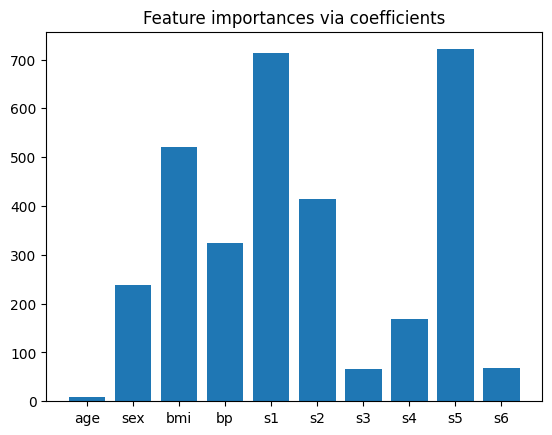

In [5]:
# Feature importance from coefficients

import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import RidgeCV

ridge = RidgeCV(alphas=np.logspace(-6, 6, num=5)).fit(X, y)
importance = np.abs(ridge.coef_)
feature_names = np.array(diabetes.feature_names)
plt.bar(height=importance, x=feature_names)
plt.title("Feature importances via coefficients")
plt.show()

In [6]:
# Selecting features with Sequential Feature Selection
from sklearn.feature_selection import SequentialFeatureSelector
from time import time

tic_fwd = time()
sfs_forward = SequentialFeatureSelector(
    ridge, n_features_to_select=2, direction="forward"
).fit(X, y)
toc_fwd = time()

tic_bwd = time()
sfs_backward = SequentialFeatureSelector(
    ridge, n_features_to_select=2, direction="backward"
).fit(X, y)
toc_bwd = time()

print(
    "Features selected by forward sequential selection: "
    f"{feature_names[sfs_forward.get_support()]}"
)
print(f"Done in {toc_fwd - tic_fwd:.3f}s")
print(
    "Features selected by backward sequential selection: "
    f"{feature_names[sfs_backward.get_support()]}"
)
print(f"Done in {toc_bwd - tic_bwd:.3f}s")

Features selected by forward sequential selection: ['bmi' 's5']
Done in 0.133s
Features selected by backward sequential selection: ['bmi' 's5']
Done in 0.425s


## L1-based feature selection

- Linear models penalized with the L1 norm have sparse solutions: many of their estimated coefficients are zero.

- In particular, sparse estimators useful for this purpose are the Lasso for regression, and of `LogisticRegression` and `LinearSVC` for classification:

In [7]:
from sklearn.feature_selection import SelectFromModel
?SelectFromModel

Init signature:
SelectFromModel(
    estimator,
    *,
    threshold=None,
    prefit=False,
    norm_order=1,
    max_features=None,
    importance_getter='auto',
)
Docstring:     
Meta-transformer for selecting features based on importance weights.

.. versionadded:: 0.17

Read more in the :ref:`User Guide <select_from_model>`.

Parameters
----------
estimator : object
    The base estimator from which the transformer is built.
    This can be both a fitted (if ``prefit`` is set to True)
    or a non-fitted estimator. The estimator should have a
    ``feature_importances_`` or ``coef_`` attribute after fitting.
    Otherwise, the ``importance_getter`` parameter should be used.

threshold : str or float, default=None
    The threshold value to use for feature selection. Features whose
    absolute importance value is greater or equal are kept while the others
    are discarded. If "median" (resp. "mean"), then the ``threshold`` value
    is the median (resp. the mean) of the feature i

In [8]:
from sklearn.svm import LinearSVC
from sklearn.datasets import load_iris
from sklearn.feature_selection import SelectFromModel
X, y = load_iris(return_X_y=True)
X.shape

(150, 4)

In [9]:
lsvc = LinearSVC(C=0.01, penalty="l1", dual=False).fit(X, y)
model = SelectFromModel(lsvc, prefit=True)
X_new = model.transform(X)
X_new.shape

(150, 3)

With SVMs and logistic-regression, the parameter C controls the sparsity: the smaller C the fewer features selected. 


With Lasso, the higher the alpha parameter, the fewer features selected.

## Feature selection as part of a pipeline

- Feature selection is usually used as a pre-processing step before doing the actual learning.

-  The recommended way to do this in scikit-learn is to use a `Pipeline`.

In [10]:
from sklearn.feature_selection import SelectFromModel
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

clf = Pipeline([
  ('feature_selection', SelectFromModel(LinearSVC(penalty="l1", dual=False))),
  ('classification', RandomForestClassifier())
])
clf.fit(X, y)

c:\Users\huawei\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Pipeline(steps=[('feature_selection',
                 SelectFromModel(estimator=LinearSVC(dual=False,
                                                     penalty='l1'))),
                ('classification', RandomForestClassifier())])

## More feature selection methods in `scikit-learn`

- Univariate feature selection 

- Recursive feature elimination (RFE)

- Tree-based feature selection

##  Principal component analysis (PCA)

## Exact PCA

- PCA is used to decompose a multivariate dataset in a set of successive orthogonal components that explain a maximum amount of the variance.

In [11]:
from sklearn.decomposition import PCA
?PCA

Init signature:
PCA(
    n_components=None,
    *,
    copy=True,
    whiten=False,
    svd_solver='auto',
    tol=0.0,
    iterated_power='auto',
    n_oversamples=10,
    power_iteration_normalizer='auto',
    random_state=None,
)
Docstring:     
Principal component analysis (PCA).

Linear dimensionality reduction using Singular Value Decomposition of the
data to project it to a lower dimensional space. The input data is centered
but not scaled for each feature before applying the SVD.

It uses the LAPACK implementation of the full SVD or a randomized truncated
SVD by the method of Halko et al. 2009, depending on the shape of the input
data and the number of components to extract.

With sparse inputs, the ARPACK implementation of the truncated SVD can be
used (i.e. through :func:`scipy.sparse.linalg.svds`). Alternatively, one
may consider :class:`TruncatedSVD` where the data are not centered.

Notice that this class only supports sparse inputs for some solvers such as
"arpack" and "c

## Case: Principal Component Analysis (PCA) on Iris Dataset

In [12]:
## Loading the Iris dataset
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
print(iris.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


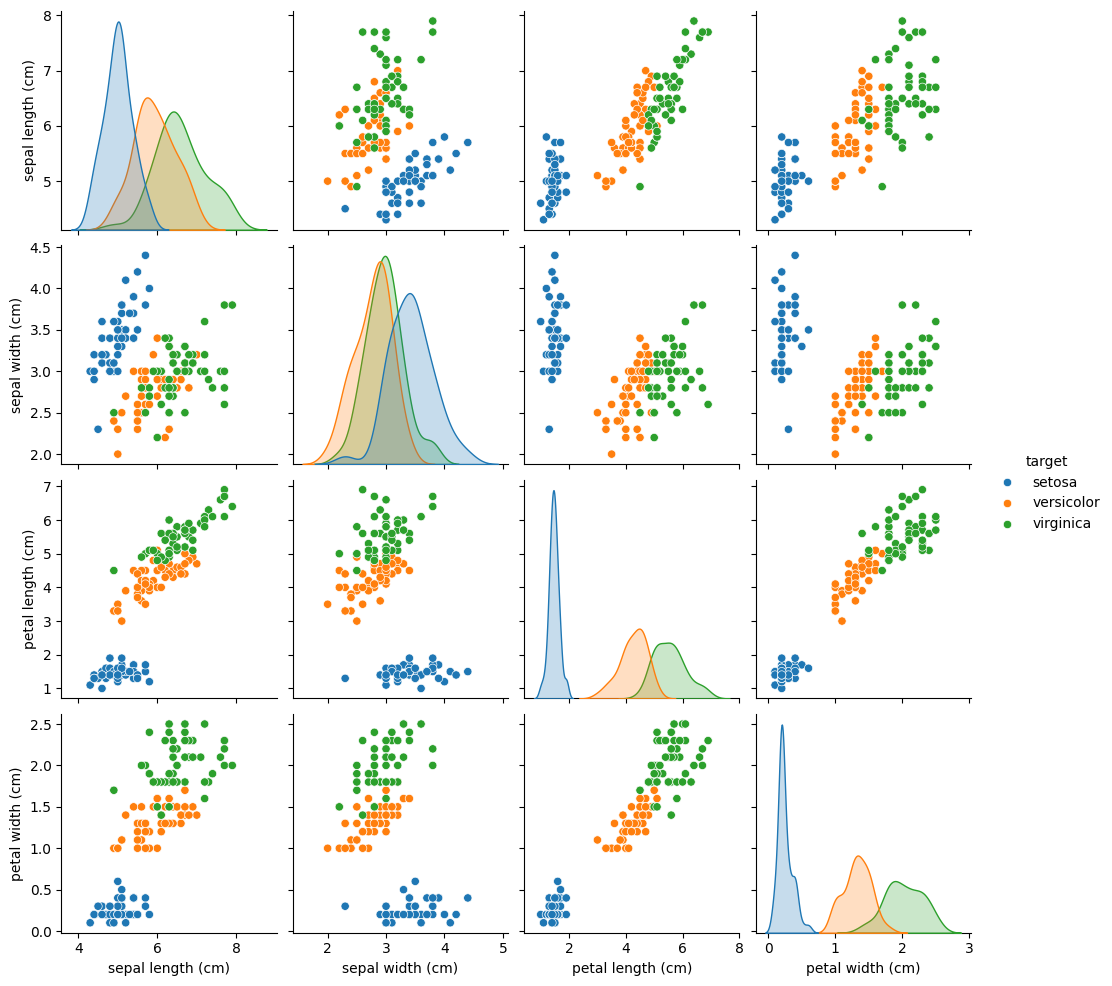

In [13]:
## Plot of pairs of features of the Iris dataset
import seaborn as sns

# Rename classes using the iris target names
iris.frame["target"] = iris.target_names[iris.target]
_ = sns.pairplot(iris.frame, hue="target")

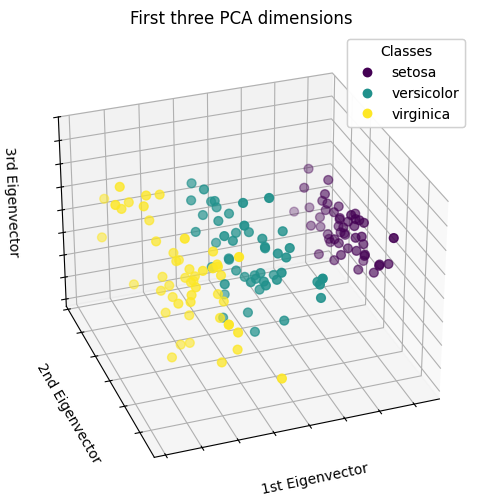

In [14]:
## Plot a PCA representation
import matplotlib.pyplot as plt

# unused but required import for doing 3d projections with matplotlib < 3.2
import mpl_toolkits.mplot3d  # noqa: F401

from sklearn.decomposition import PCA

fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

X_reduced = PCA(n_components=3).fit_transform(iris.data)
scatter = ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    c=iris.target,
    s=40,
)

ax.set(
    title="First three PCA dimensions",
    xlabel="1st Eigenvector",
    ylabel="2nd Eigenvector",
    zlabel="3rd Eigenvector",
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

# Add a legend
legend1 = ax.legend(
    scatter.legend_elements()[0],
    iris.target_names.tolist(),
    loc="upper right",
    title="Classes",
)
ax.add_artist(legend1)
plt.show()

## Incremental PCA

- `PCA` is very useful, but has certain limitations for large datasets.
    + `PCA` only supports batch processing, which means all of the data to be processed must fit in main memory.

- `IncrementalPCA` allows for partial computations which almost exactly match the results of PCA while processing the data in a minibatch fashion.
    + Using its `partial_fit` method on chunks of data fetched sequentially from the local hard drive or a network database.
    + Calling its fit method on a memory mapped file using `numpy.memmap`

In [15]:
from sklearn.decomposition import IncrementalPCA
?IncrementalPCA

Init signature:
IncrementalPCA(
    n_components=None,
    *,
    whiten=False,
    copy=True,
    batch_size=None,
)
Docstring:     
Incremental principal components analysis (IPCA).

Linear dimensionality reduction using Singular Value Decomposition of
the data, keeping only the most significant singular vectors to
project the data to a lower dimensional space. The input data is centered
but not scaled for each feature before applying the SVD.

Depending on the size of the input data, this algorithm can be much more
memory efficient than a PCA, and allows sparse input.

This algorithm has constant memory complexity, on the order
of ``batch_size * n_features``, enabling use of np.memmap files without
loading the entire file into memory. For sparse matrices, the input
is converted to dense in batches (in order to be able to subtract the
mean) which avoids storing the entire dense matrix at any one time.

The computational overhead of each SVD is
``O(batch_size * n_features ** 2)``, but

In [16]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA, IncrementalPCA

In [17]:
iris = load_iris()
X = iris.data
y = iris.target

In [18]:
n_components = 2
ipca = IncrementalPCA(n_components=n_components, batch_size=10)
X_ipca = ipca.fit_transform(X)

pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X)

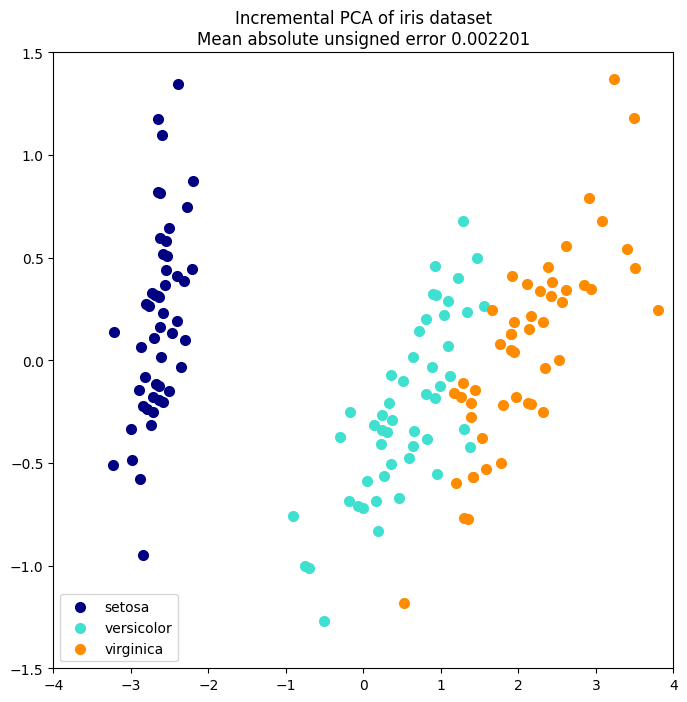

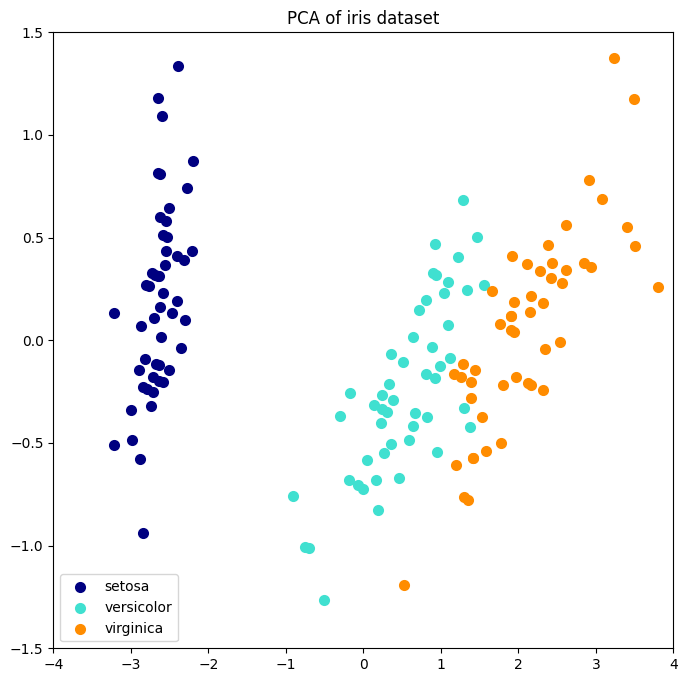

In [19]:
colors = ["navy", "turquoise", "darkorange"]

for X_transformed, title in [(X_ipca, "Incremental PCA"), (X_pca, "PCA")]:
    plt.figure(figsize=(8, 8))
    for color, i, target_name in zip(colors, [0, 1, 2], iris.target_names):
        plt.scatter(
            X_transformed[y == i, 0],
            X_transformed[y == i, 1],
            color=color,
            lw=2,
            label=target_name,
        )

    if "Incremental" in title:
        err = np.abs(np.abs(X_pca) - np.abs(X_ipca)).mean()
        plt.title(title + " of iris dataset\nMean absolute unsigned error %.6f" % err)
    else:
        plt.title(title + " of iris dataset")
    plt.legend(loc="best", shadow=False, scatterpoints=1)
    plt.axis([-4, 4, -1.5, 1.5])

plt.show()

## Faces recognition example using eigenfaces and SVMs

In [20]:
from time import time

import matplotlib.pyplot as plt
from scipy.stats import loguniform

from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [21]:
# Download the data, if not already on disk and load it as numpy arrays
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

# introspect the images arrays to find the shapes (for plotting)
n_samples, h, w = lfw_people.images.shape

# for machine learning we use the 2 data directly (as relative pixel
# positions info is ignored by this model)
X = lfw_people.data
n_features = X.shape[1]

# the label to predict is the id of the person
y = lfw_people.target
target_names = lfw_people.target_names
n_classes = target_names.shape[0]

print("Total dataset size:")
print("n_samples: %d" % n_samples)
print("n_features: %d" % n_features)
print("n_classes: %d" % n_classes)

Total dataset size:
n_samples: 1288
n_features: 1850
n_classes: 7


In [22]:
# Split into a training set and a test and keep 25% of the data for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [23]:
# Compute a PCA (eigenfaces) on the face dataset (treated as unlabeled dataset): unsupervised feature extraction / dimensionality reduction
n_components = 150

print(
    "Extracting the top %d eigenfaces from %d faces" % (n_components, X_train.shape[0])
)
t0 = time()
pca = PCA(n_components=n_components, svd_solver="randomized", whiten=True).fit(X_train)
print("done in %0.3fs" % (time() - t0))

eigenfaces = pca.components_.reshape((n_components, h, w))

print("Projecting the input data on the eigenfaces orthonormal basis")
t0 = time()
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)
print("done in %0.3fs" % (time() - t0))

Extracting the top 150 eigenfaces from 966 faces
done in 0.163s
Projecting the input data on the eigenfaces orthonormal basis
done in 0.010s


In [24]:
# Train a SVM classification model
print("Fitting the classifier to the training set")
t0 = time()
param_grid = {
    "C": loguniform(1e3, 1e5),
    "gamma": loguniform(1e-4, 1e-1),
}
clf = RandomizedSearchCV(
    SVC(kernel="rbf", class_weight="balanced"), param_grid, n_iter=10
)
clf = clf.fit(X_train_pca, y_train)
print("done in %0.3fs" % (time() - t0))
print("Best estimator found by grid search:")
print(clf.best_estimator_)

Fitting the classifier to the training set
done in 3.393s
Best estimator found by grid search:
SVC(C=1675.4486157259278, class_weight='balanced', gamma=0.003322067338888804)


Predicting people's names on the test set
done in 0.032s
                   precision    recall  f1-score   support

     Ariel Sharon       0.82      0.69      0.75        13
     Colin Powell       0.74      0.87      0.80        60
  Donald Rumsfeld       0.78      0.67      0.72        27
    George W Bush       0.89      0.96      0.92       146
Gerhard Schroeder       0.91      0.80      0.85        25
      Hugo Chavez       0.89      0.53      0.67        15
       Tony Blair       0.93      0.75      0.83        36

         accuracy                           0.85       322
        macro avg       0.85      0.75      0.79       322
     weighted avg       0.85      0.85      0.85       322



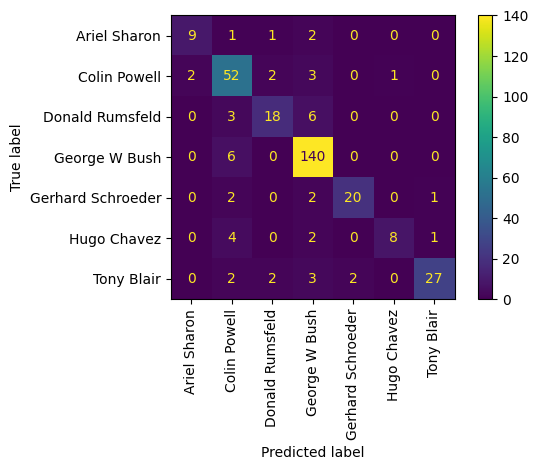

In [25]:
# Quantitative evaluation of the model quality on the test set
print("Predicting people's names on the test set")
t0 = time()
y_pred = clf.predict(X_test_pca)
print("done in %0.3fs" % (time() - t0))

print(classification_report(y_test, y_pred, target_names=target_names))
ConfusionMatrixDisplay.from_estimator(
    clf, X_test_pca, y_test, display_labels=target_names, xticks_rotation="vertical"
)
plt.tight_layout()
plt.show()

In [26]:
# Qualitative evaluation of the predictions using matplotlib
def plot_gallery(images, titles, h, w, n_row=3, n_col=4):
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=0.01, right=0.99, top=0.90, hspace=0.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())

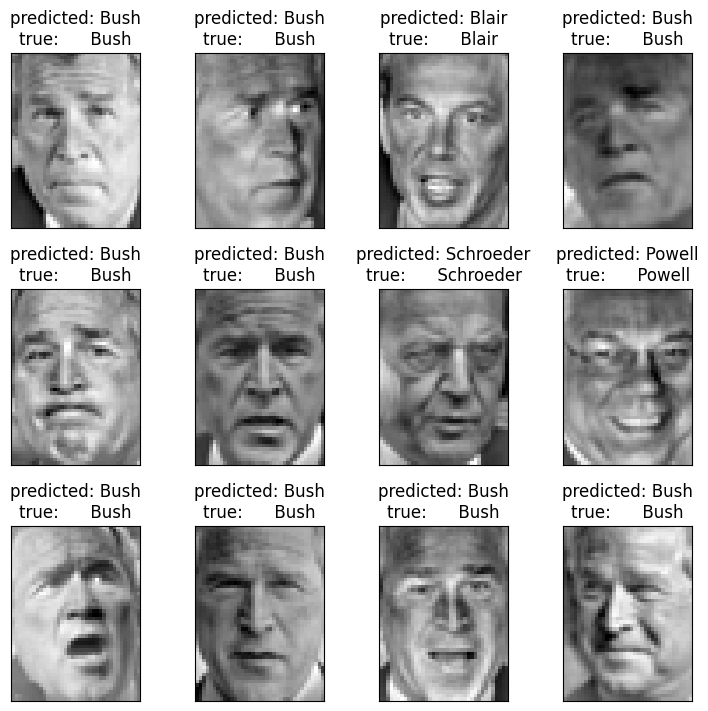

In [27]:
# def plot_gallery(images, titles, h, w, n_row=3, n_col=4):
def title(y_pred, y_test, target_names, i):
    pred_name = target_names[y_pred[i]].rsplit(" ", 1)[-1]
    true_name = target_names[y_test[i]].rsplit(" ", 1)[-1]
    return "predicted: %s\ntrue:      %s" % (pred_name, true_name)


prediction_titles = [
    title(y_pred, y_test, target_names, i) for i in range(y_pred.shape[0])
]

plot_gallery(X_test, prediction_titles, h, w)

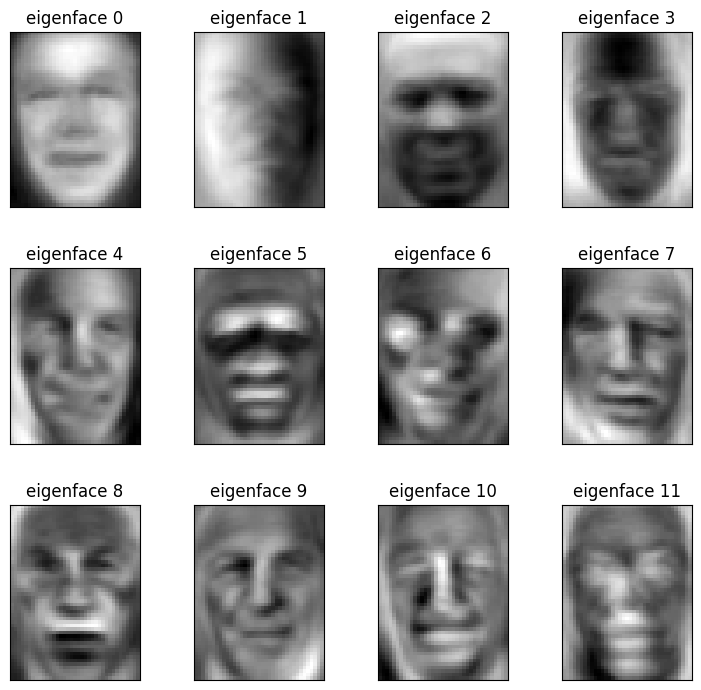

In [28]:
# plot the gallery of the most significative eigenfaces
eigenface_titles = ["eigenface %d" % i for i in range(eigenfaces.shape[0])]
plot_gallery(eigenfaces, eigenface_titles, h, w)

plt.show()

## Linear Discriminant Analysis (LDA)

Linear Discriminant Analysis (`LinearDiscriminantAnalysis`) and Quadratic Discriminant Analysis (`QuadraticDiscriminantAnalysis`) are two classic classifiers, with, as their names suggest, a linear and a quadratic decision surface, respectively.

These classifiers are attractive because they have closed-form solutions that can be easily computed, are inherently multiclass, have proven to work well in practice, and have no hyperparameters to tune.

## Dimensionality reduction using Linear Discriminant Analysis
`LinearDiscriminantAnalysis` can be used to perform supervised dimensionality reduction, by projecting the input data to a linear subspace consisting of the directions which maximize the separation between classes (in a precise sense discussed in the mathematics section below). The dimension of the output is necessarily less than the number of classes, so this is in general a rather strong dimensionality reduction, and only makes sense in a multiclass setting.

This is implemented in the transform method. The desired dimensionality can be set using the `n_components` parameter. This parameter has no influence on the fit and predict methods.

In [29]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
?LinearDiscriminantAnalysis

Init signature:
LinearDiscriminantAnalysis(
    solver='svd',
    shrinkage=None,
    priors=None,
    n_components=None,
    store_covariance=False,
    tol=0.0001,
    covariance_estimator=None,
)
Docstring:     
Linear Discriminant Analysis.

A classifier with a linear decision boundary, generated by fitting class
conditional densities to the data and using Bayes' rule.

The model fits a Gaussian density to each class, assuming that all classes
share the same covariance matrix.

The fitted model can also be used to reduce the dimensionality of the input
by projecting it to the most discriminative directions, using the
`transform` method.

.. versionadded:: 0.17

For a comparison between
:class:`~sklearn.discriminant_analysis.LinearDiscriminantAnalysis`
and :class:`~sklearn.discriminant_analysis.QuadraticDiscriminantAnalysis`, see
:ref:`sphx_glr_auto_examples_classification_plot_lda_qda.py`.

Read more in the :ref:`User Guide <lda_qda>`.

Parameters
----------
solver : {'svd', 'lsqr'

## Case: Comparison of LDA and PCA 2D projection of Iris dataset

In [30]:
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [31]:
iris = datasets.load_iris()

X = iris.data
y = iris.target
target_names = iris.target_names

In [32]:
pca = PCA(n_components=2)
X_r = pca.fit(X).transform(X)

lda = LinearDiscriminantAnalysis(n_components=2)
X_r2 = lda.fit(X, y).transform(X)

explained variance ratio (first two components): [0.92461872 0.05306648]


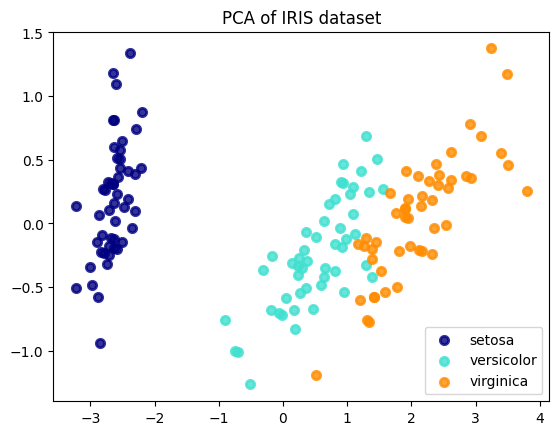

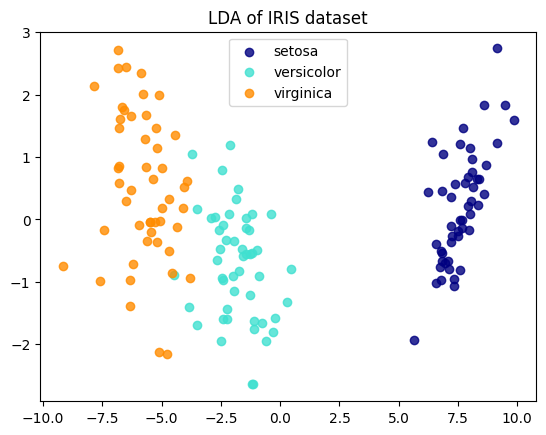

In [33]:
# Percentage of variance explained for each components
print(
    "explained variance ratio (first two components): %s"
    % str(pca.explained_variance_ratio_)
)

plt.figure()
colors = ["navy", "turquoise", "darkorange"]
lw = 2

for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(
        X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=0.8, lw=lw, label=target_name
    )
plt.legend(loc="best", shadow=False, scatterpoints=1)
plt.title("PCA of IRIS dataset")

plt.figure()
for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(
        X_r2[y == i, 0], X_r2[y == i, 1], alpha=0.8, color=color, label=target_name
    )
plt.legend(loc="best", shadow=False, scatterpoints=1)
plt.title("LDA of IRIS dataset")

plt.show()

## Summary for `Dimension Reduction`

- Feature Selection

- PCA

- LDA